### 선형 회귀 실습 문제

# Tips Dataset
: 레스토랑의 총 식사 금액을 이용해 손님이 지불할 팁 금액을 예측하는 선형 회귀 모델 구현.

#### Step1. 데이터 불러오기 및 전처리

**사용 데이터: Tips Dataset**

- 데이터: 244개
- 입력 특징: 1개 (총 식사 금액 (`total_bill`))
- 정답: 팁 금액(`tip`)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `total_bill` | 총 식사 금액 | 식사에 청구된 총 금액 |
| `tip` | 팁 금액 | 종업원에게 지불한 팁 |
| `sex` | 성별 | 계산한 손님의 성별 |
| `smoker` | 흡연 여부 | 흡연자 여부 |
| `day` | 요일 | 식사한 요일 |
| `time` | 식사 시간 | Lunch 또는 Dinner |
| `size` | 인원수 | 테이블의 손님 수 |

**실습 조건**
- 입력값(X): `total_bill`
- 정답(y): `tip`
- 결측치가 있는지 확인하고, 필요한 경우 처리한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 입력값은 학습 데이터의 평균과 표준편차를 이용해 표준화한다.
- `total_bill`과 `tip`의 관계를 산점도로 먼저 확인한다.

In [241]:
import torch
import pandas as pd
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np

In [242]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

df = pd.read_csv(url)
print(df.isnull().sum())
# 이번 실습에 필요한 두 열만 사용
df = df[["total_bill", "tip"]].dropna().copy()

x = torch.tensor(df[['total_bill']].values, dtype=torch.float32)
y = torch.tensor(df[['tip']].values, dtype=torch.float32)

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


In [243]:
indices = torch.randperm(len(x))
split = int(len(x)*0.8)

train_indices = indices[:split]
test_indices = indices[split:]

X_train = x[train_indices]
X_test = x[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

mean = X_train.mean()
std = X_train.std().clamp(1e-8)

x_train = (X_train - mean)/std
x_test = (X_test-mean)/std

In [244]:
BATCH_SIZE = 32

train_DS = TensorDataset(x_train,y_train)
test_DS = TensorDataset(x_test, y_test)

train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=False)

N = len(train_DL.dataset)

#### Step2. 모델 만들기

- 입력 노드: 1개 (`total_bill`)
- 출력 노드: 1개 (`tip`)
- 활성화 함수: 사용하지 않음
- 모델: `nn.Linear`

In [245]:
model = nn.Linear(1,1)

#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: MSELoss
- 학습률(LR): 0.01부터 시작
- Epoch: 200
- Batch size: 32

In [246]:
LR = 1e-2
EPOCH = 200

loss_history =[]

optimizer = optim.SGD(model.parameters(), lr=LR)
criterion = nn.MSELoss()

model.train()
for ep in range(EPOCH):
    rloss = 0

    for x_batch, y_batch in train_DL:
        y_hat = model(x_batch)

        loss = criterion(y_hat, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item()*x_batch.shape[0]
    loss_e = rloss/N
    loss_history.append(loss_e)

    if ep % 10 == 0:
        print(f'Epoch : {ep+1} | loss : {loss_e:.4f}')

Epoch : 1 | loss : 15.1267
Epoch : 11 | loss : 1.8467
Epoch : 21 | loss : 1.0908
Epoch : 31 | loss : 1.0366
Epoch : 41 | loss : 1.0262
Epoch : 51 | loss : 1.0245
Epoch : 61 | loss : 1.0262
Epoch : 71 | loss : 1.0260
Epoch : 81 | loss : 1.0258
Epoch : 91 | loss : 1.0262
Epoch : 101 | loss : 1.0247
Epoch : 111 | loss : 1.0262
Epoch : 121 | loss : 1.0254
Epoch : 131 | loss : 1.0284
Epoch : 141 | loss : 1.0243
Epoch : 151 | loss : 1.0396
Epoch : 161 | loss : 1.0297
Epoch : 171 | loss : 1.0248
Epoch : 181 | loss : 1.0272
Epoch : 191 | loss : 1.0269


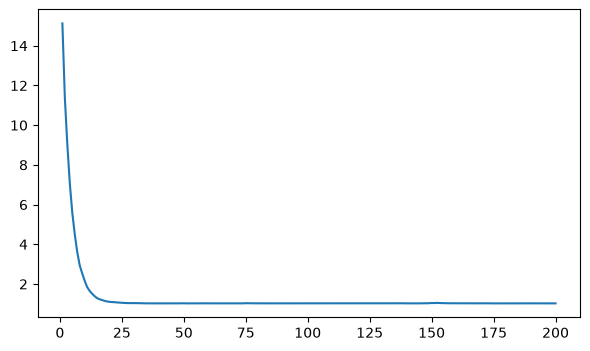

In [247]:
plt.figure(figsize=(7,4))
plt.plot(range(1,EPOCH+1),loss_history)

#### Step4. 모델 테스트하기


In [ ]:
model.eval()
with torch.no_grad():
    y_pred = model(x_test)

test_loss = criterion(y_pred, y_test).item()

print(test_loss)

1.1249433755874634


#### Step5. 테스트 결과 시각화

**문제**
- 첫 번째 그래프: 테스트 데이터의 실제 산점도와 모델의 예측 회귀선을 함께 표시.
- 두 번째 그래프: 실제 팁 금액을 x축, 예측 팁 금액을 y축으로 하는 산점도를 작성.
- 두 번째 그래프에 완벽한 예측을 나타내는 기준선(y=x)을 추가.
- 그래프의 축 이름과 제목을 적절히 표시.

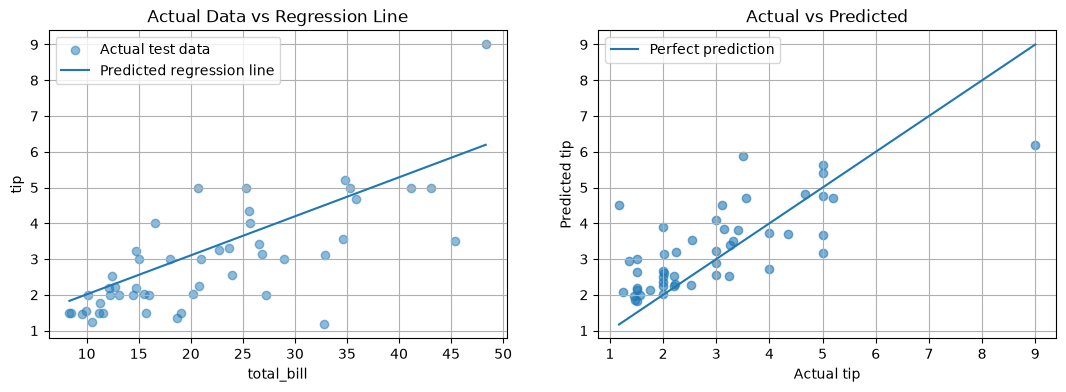

In [249]:
sort_indices = torch.argsort(X_test.squeeze())

X_sorted = X_test[sort_indices]
x_sorted = x_test[sort_indices]
y_pred_sorted = model(x_sorted)

fig, axes = plt.subplots(1,2,figsize=(13,4))

axes[0].scatter(X_test.numpy(), y_test.numpy(), alpha=0.5, label='Actual test data')
axes[0].plot(X_sorted.numpy(), y_pred_sorted.detach().numpy(), label='Predicted regression line')
axes[0].set_xlabel('total_bill')
axes[0].set_ylabel('tip')
axes[0].set_title('Actual Data vs Regression Line')
axes[0].legend()
axes[0].grid(True)

axes[1].scatter(y_test.numpy(), y_pred.detach().numpy(), alpha=0.6)
axes[1].plot([y_test.min().item(), y_test.max().item()], [y_test.min().item(), y_test.max().item()], label='Perfect prediction')
axes[1].set_xlabel('Actual tip')
axes[1].set_ylabel('Predicted tip')
axes[1].set_title('Actual vs Predicted')
axes[1].legend()
axes[1].grid(True)

#### STEP 6. 파라미터 개수 확인

In [250]:
print(sum(p.numel() for p in model.parameters()))

2
